# Julia から Wolfram Engine を呼び出す — 微分方程式を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分・微分・方程式・数列・確率・複素数平面編の続き）。

**Wolfram の厳密解** と **Julia で書いた数値解法** を並べて比べます。

- 微分方程式 `DSolve` → 一般解・特殊解を表示し，**Julia の関数**として使う
- 方向場（傾きの図）に解曲線を重ねる
- オイラー法などを Julia で実装し，厳密解との誤差を調べる
- 応用：放射性崩壊，冷却，空気抵抗，ロジスティック方程式，単振動・減衰振動
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "Plots"])
# Pkg.add(url="https://github.com/ujimushi/PlotsGRBackendFontJaEmoji.jl")   # グラフの日本語表示用

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 基本：`DSolve`

未知関数は `y[x]`，導関数は `y'[x]`，`y''[x]` と書きます。等号は `==` です。  
一般解には任意定数 $c_1, c_2, \dots$（Wolfram では `C[1]`, `C[2]`）が含まれます。

In [3]:
weval(W`DSolve[y'[x] == k y[x], y[x], x]`)              # 一般解（y(x) → 解 という規則で返る）

W`List[List[Rule[y[x], Times[Power[E, Times[k, x]], C[1]]]]]`

In [4]:
weval(W`DSolve[{y'[x] == k y[x], y[0] == a}, y[x], x]`)     # 初期条件つき

W`List[List[Rule[y[x], Times[a, Power[E, Times[k, x]]]]]]`

## 2. きれいに表示するための関数

In [5]:
# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = heldtex(s)

# 任意定数 c_1 を C_1 と表示する
ctex(s) = replace(s, r"\bc_(\d)" => s"C_\1")

# 微分方程式の表示：y'(x) を y'，y(x) を y と略す（y(0) = 1 のような初期条件はそのまま）
function eqtex(eq::AbstractString, y="y", x="x")
    s = replace(texheld(eq), "\\left($y'\\right)'" => "$y''")
    replace(s, "$y''($x)" => "$y''", "$y'($x)" => "$y'", "$y($x)" => y)
end

eqtex (generic function with 3 methods)

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- 任意定数 `C[1]`, `C[2]` → Julia の変数 `C1`, `C2`

## 4. 微分方程式を解く → 解を Julia の関数にする

`dsolve(方程式)` または `dsolve([方程式, 初期条件, ...])` にまとめます。

- 戻り値は `(Wolfram の式, Julia の関数)`。
- Julia の関数の引数は **`(x, パラメータ..., 任意定数...)`** の順です。  
  パラメータ（$k$ など）は `params=[:k]` で指定し，任意定数 $C_1, C_2$ は自動で後ろに付きます。
- 未知関数や変数の名前は `y="T", x="t"` で変えられます。

In [6]:
function dsolve(eqs::Vector{String}; y="y", x="x", params=Symbol[], branch=1, simplify=true)
    res = weval(MathLink.parseexpr("$y[$x] /. DSolve[{$(join(eqs, ", "))}, $y[$x], $x]"))
    res isa MathLink.WExpr && res.head == W"List" && !isempty(res.args) ||
        error("DSolve では解けませんでした。数値解法を使ってください。")
    simplify && (res = weval(W"FullSimplify"(res)))
    sols = res.args                                     # 解が複数（枝分かれ）のこともある
    showtex(join(eqtex.(eqs, y, x), ",\\quad ") * "\\implies " *
            join(("$y = " * ctex(tex(s)) for s in sols), "\\quad\\text{または}\\quad "))
    w = sols[branch]
    consts = [Symbol("C", i) for i in 1:4 if occursin("C[$i]", string(w))]
    return w, to_function(w, Symbol(x), params..., consts...)
end
dsolve(eq::String; kw...) = dsolve([eq]; kw...)

dsolve (generic function with 2 methods)

### 一般解と特殊解

In [7]:
gw, g = dsolve("y'[x] == k y[x]"; params=[:k])           # 一般解： g(x, k, C1)
_, p = dsolve(["y'[x] == k y[x]", "y[0] == a"]; params=[:k, :a])   # 初期条件つき： p(x, k, a)

g(1.0, 0.5, 2), p(1.0, 0.5, 2), 2 * exp(0.5)

(3.2974425414002564, 3.2974425414002564, 3.2974425414002564)

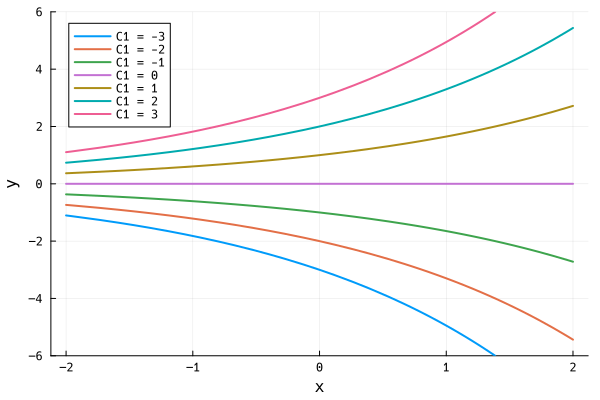

In [8]:
# 任意定数 C1 を変えると，解曲線の族になる（k = 1/2）
plot(; xlabel="x", ylabel="y", legend=:topleft, ylims=(-6, 6))
for C in -3:3
    plot!(x -> g(x, 0.5, C), -2, 2; label="C1 = $C", lw=2)
end
plot!()

**検算**：解を元の方程式に代入して，左辺 − 右辺が 0 になることを Wolfram で確かめます。

In [9]:
chk = weval(W"Simplify"(W"Plus"(W"D"(gw, W"x"), W"Times"(-1, W"k", gw))))      # y' - k y に一般解を代入
showtex("y' - k y = " * tex(chk))

### いろいろな微分方程式

In [10]:
dsolve("y'[x] == x y[x]")                                # 変数分離形
dsolve("y'[x] == 2 x y[x]^2")
dsolve(["y'[x] == Cos[x] y[x]", "y[0] == 1"])
dsolve("y'[x] + y[x] == x")                              # 1 階線形
dsolve(["y'[x] + y[x] == x", "y[0] == 1"])
dsolve(["x y'[x] == y[x] + x^2", "y[1] == 2"])
dsolve("y''[x] - 3 y'[x] + 2 y[x] == Exp[3 x]");         # 2 階線形（定数係数）

解が複数の枝に分かれることもあります。`branch=2` で 2 番目の解を Julia の関数にします。

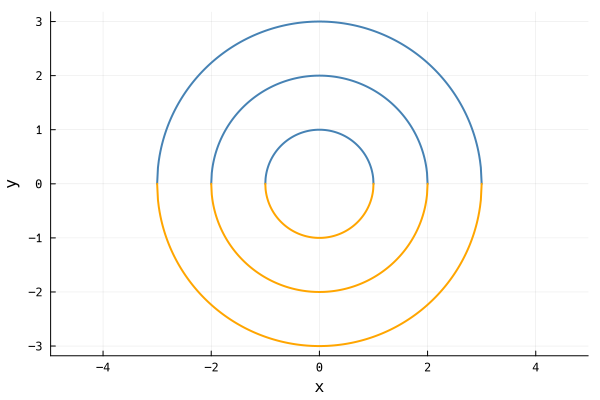

In [11]:
_, lower = dsolve("y'[x] == -x/y[x]")                    # 円 x² + y² = 2C の下半分と上半分
_, upper = dsolve("y'[x] == -x/y[x]"; branch=2)

plot(; aspect_ratio=1, xlabel="x", ylabel="y", legend=false)
for C in (0.5, 2, 4.5)
    r = sqrt(2C); xs = range(-r, r; length=400)
    plot!(xs, [upper(x, C) for x in xs]; color=:steelblue, lw=2)
    plot!(xs, [lower(x, C) for x in xs]; color=:orange, lw=2)
end
plot!()

## 5. 方向場と解曲線

$y' = f(x, y)$ は「点 $(x, y)$ での傾き」を決めています。各点に傾きを表す小さな矢印を描いたものが方向場です。  
解曲線は，どの点でも矢印に接しています。

In [12]:
# 方向場を描く。矢印は画面上で同じ長さ（格子 1 マスの len 倍）にそろえる
function slopefield(f, xr, yr; n=21, len=0.8, kw...)
    xs = range(xr...; length=n); ys = range(yr...; length=n)
    X = [x for x in xs for y in ys]; Y = [y for x in xs for y in ys]
    S = f.(X, Y)
    dx, dy = step(xs), step(ys)                         # 格子 1 マスの大きさ（x 軸と y 軸で縮尺が違ってもよい）
    N = sqrt.(1 .+ (S .* dx ./ dy) .^ 2)                # 画面上での矢印の長さで割ってそろえる
    U = len * dx ./ N; V = S .* U
    quiver(X .- U ./ 2, Y .- V ./ 2; quiver=(U, V), color=:gray, xlabel="x", ylabel="y",
           xlims=xr, ylims=yr, legend=:topleft, kw...)
end

slopefield (generic function with 1 method)

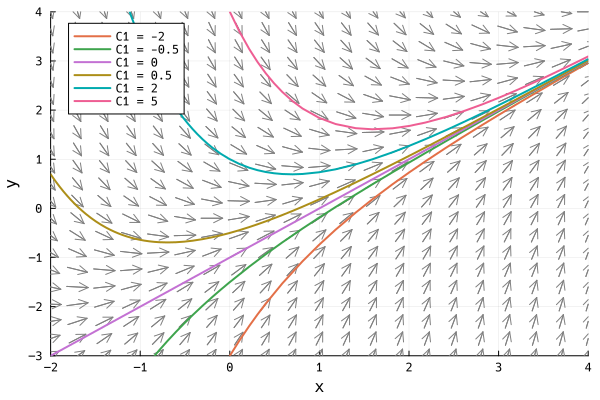

In [13]:
sw, s = dsolve("y'[x] == x - y[x]")                      # 一般解： s(x, C1)

slopefield((x, y) -> x - y, (-2, 4), (-3, 4))
for C in (-2, -0.5, 0, 0.5, 2, 5)
    plot!(x -> s(x, C), -2, 4; lw=2, label="C1 = $C")
end
plot!()

## 6. オイラー法：数値解と厳密解を比べる

$y' = f(x, y)$，$y(x_0) = y_0$ を，刻み幅 $h$ で
$$y_{n+1} = y_n + h\, f(x_n, y_n)$$
と順に計算するのがオイラー法です。改良版（ホイン法，4 次のルンゲ・クッタ法）も同じ形で書けます。

In [14]:
# 1 ステップ進める規則
euler_step(f, x, y, h) = y + h * f(x, y)
function heun_step(f, x, y, h)
    k1 = f(x, y); k2 = f(x + h, y + h * k1)
    return y + h / 2 * (k1 + k2)
end
function rk4_step(f, x, y, h)
    k1 = f(x, y); k2 = f(x + h / 2, y + h / 2 * k1); k3 = f(x + h / 2, y + h / 2 * k2); k4 = f(x + h, y + h * k3)
    return y + h / 6 * (k1 + 2k2 + 2k3 + k4)
end

# x0 から n ステップ進める。y0 は数でもベクトルでもよい。戻り値は (x の列, y の列)
function ode_solve(step, f, x0, y0, h, n)
    xs = [x0 + i * h for i in 0:n]
    ys = [float.(y0)]
    for i in 1:n
        push!(ys, step(f, xs[i], ys[end], h))
    end
    return xs, ys
end

ode_solve (generic function with 1 method)

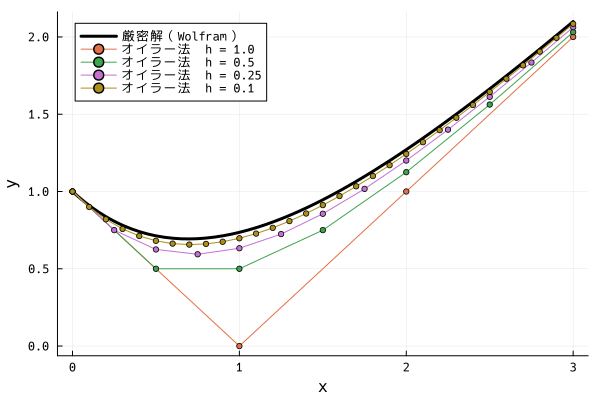

In [15]:
f(x, y) = x - y
_, exact = dsolve(["y'[x] == x - y[x]", "y[0] == 1"])    # 厳密解

plot(exact, 0, 3; lw=3, color=:black, label="厳密解（Wolfram）", xlabel="x", ylabel="y", legend=:topleft)
for h in (1.0, 0.5, 0.25, 0.1)
    xs, ys = ode_solve(euler_step, f, 0.0, 1.0, h, round(Int, 3 / h))
    plot!(xs, ys; marker=:circle, ms=3, label="オイラー法  h = $h")
end
plot!()

**誤差の減り方**：$x = 3$ での誤差を，刻み幅 $h$ を半分ずつにして調べます。  
オイラー法は $h$ を半分にすると誤差も約半分（1 次），ホイン法は約 $\frac14$（2 次），ルンゲ・クッタ法は約 $\frac1{16}$（4 次）になります。

In [16]:
hs = [1 / 2^k for k in 1:8]
err(step) = [abs(ode_solve(step, f, 0.0, 1.0, h, round(Int, 3 / h))[2][end] - exact(3.0)) for h in hs]
e1, e2, e4 = err(euler_step), err(heun_step), err(rk4_step)

println(rpad("h", 12), rpad("Euler", 24), rpad("Heun", 24), "RK4")
for i in eachindex(hs)
    println(rpad(hs[i], 12), rpad(e1[i], 24), rpad(e2[i], 24), e4[i])
end

h           Euler                   Heun                    RK4
0.5         0.06832413673572812     0.019635152815053125    0.00023681013743104273
0.25        0.03622143268757139     0.0038234398334004993   1.1984340494652912e-5
0.125       0.01843632920828364     0.0008581538136915867   6.745806562236112e-7
0.0625      0.00928172301527086     0.00020403334472351986  4.001685827148549e-8
0.03125     0.004654802143970738    4.9786400889040294e-5   2.436692181362332e-9
0.015625    0.0023306581836703977   1.2299137632787449e-5   1.5032197708819695e-10
0.0078125   0.0011661157805633593   3.056669294565495e-6    9.333422923418766e-12
0.00390625  0.0005832511694374709   7.619224224875154e-7    5.81312775693732e-13


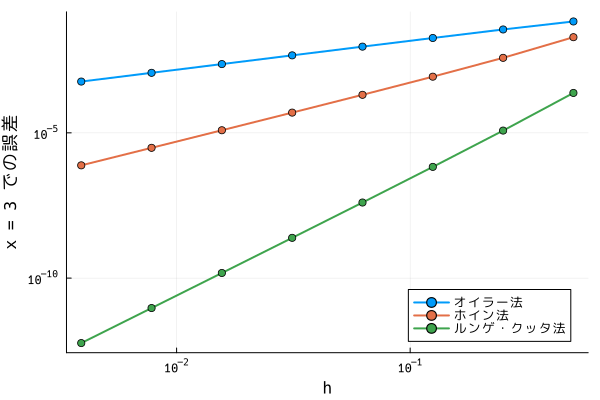

In [17]:
plot(hs, [e1 e2 e4]; xscale=:log10, yscale=:log10, marker=:circle, lw=2,
     label=["オイラー法" "ホイン法" "ルンゲ・クッタ法"], xlabel="h", ylabel="x = 3 での誤差", legend=:bottomright)

## 7. 応用

### 7.1 放射性崩壊と半減期

$N' = -kN$（減る速さが現在の量に比例）。半減期は $N(t) = \frac12 N_0$ となる $t$ です。

In [18]:
Nw, Nf = dsolve(["y'[t] == -k y[t]", "y[0] == a"]; y="y", x="t", params=[:k, :a])

hw = weval(W`t /. First[Solve[Exp[-k t] == 1/2, t, Reals]]`)
showtex("\\text{半減期}\\quad T = " * tex(hw))
halflife = to_function(hw, :k)

#to_function##0 (generic function with 1 method)

In [19]:
# 炭素 14 の半減期は約 5730 年 → 崩壊定数 k = log 2 / 5730
k14 = log(2) / 5730
@show halflife(k14)

# 炭素 14 が元の 20% になっていた試料の年代：N(t)/N0 = 0.2 を解く
age = log(1 / 0.2) / k14
@show age Nf(age, k14, 1.0);

halflife(k14) = 5730.0
age = 13304.647983704586
Nf(age, k14, 1.0) = 0.2


### 7.2 ニュートンの冷却法則

$T' = -k(T - T_{\text{室温}})$。室温 20℃ の部屋に 90℃ のお茶を置き，10 分後に 60℃ だったとします。

In [20]:
Tw, Tf = dsolve(["T'[t] == -k (T[t] - 20)", "T[0] == 90"]; y="T", x="t", params=[:k])

# 10 分後に 60℃ → k を厳密に求める
kw = weval(MathLink.parseexpr("k /. First[Solve[20 + 70 Exp[-10 k] == 60, k, Reals]]"))
showtex("k = " * tex(kw))
kc = to_value(kw)

# 40℃ になる時刻
tw = weval(MathLink.parseexpr("t /. First[Solve[20 + 70 Exp[-k t] == 40 /. k -> Log[7/4]/10, t, Reals]]"))
showtex("T = 40 \\text{ となる時刻}\\quad t = " * tex(tw))
t40 = to_value(tw)

22.38612625846667

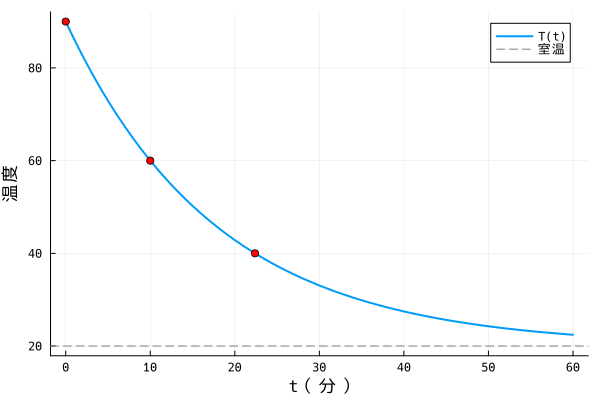

In [21]:
plot(t -> Tf(t, kc), 0, 60; lw=2, label="T(t)", xlabel="t（分）", ylabel="温度")
hline!([20]; color=:gray, ls=:dash, label="室温")
scatter!([0, 10, t40], [90, 60, 40]; color=:red, label="")

### 7.3 空気抵抗のある落下

$v' = g - kv$（速さに比例する抵抗）。十分時間がたつと，終端速度 $\frac{g}{k}$ に近づきます。

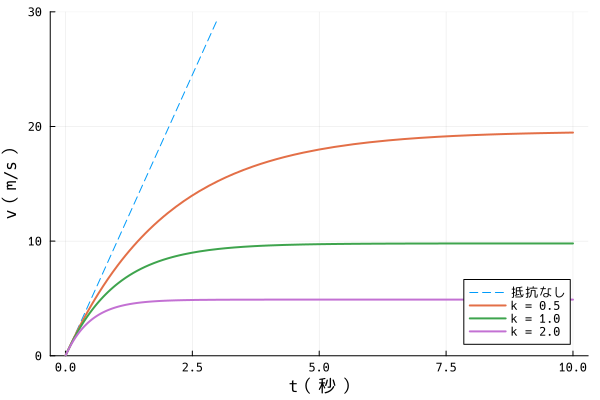

In [22]:
vw, vf = dsolve(["v'[t] == g - k v[t]", "v[0] == 0"]; y="v", x="t", params=[:g, :k])
vinf = weval(W"Limit"(vw, W"Rule"(W"t", W"Infinity"), W"Rule"(W"Assumptions", W`k > 0`)))
showtex("\\lim_{t\\to\\infty} v = " * tex(vinf))

plot(t -> 9.8t, 0, 3; ls=:dash, label="抵抗なし", xlabel="t（秒）", ylabel="v（m/s）", ylims=(0, 30))
for k in (0.5, 1.0, 2.0)
    plot!(t -> vf(t, 9.8, k), 0, 10; lw=2, label="k = $k")
end
plot!(; legend=:bottomright)

### 7.4 ロジスティック方程式

$y' = r y\left(1 - \dfrac{y}{K}\right)$：はじめは指数関数的に増え，環境収容力 $K$ に近づくと頭打ちになります。

In [23]:
Lw, L = dsolve(["y'[t] == r y[t] (1 - y[t]/K)", "y[0] == a"]; x="t", params=[:r, :K, :a])
Linf = weval(W"Limit"(Lw, W"Rule"(W"t", W"Infinity"), W"Rule"(W"Assumptions", W`r > 0 && a > 0 && K > 0`)))
showtex("\\lim_{t\\to\\infty} y = " * tex(Linf))

┌ Warning: DSolve::ifun: Inverse functions are being used by DSolve, so some solutions
│     may not be found.
└ @ MathLink ~/.julia/packages/MathLink/WEvUg/src/eval.jl:16


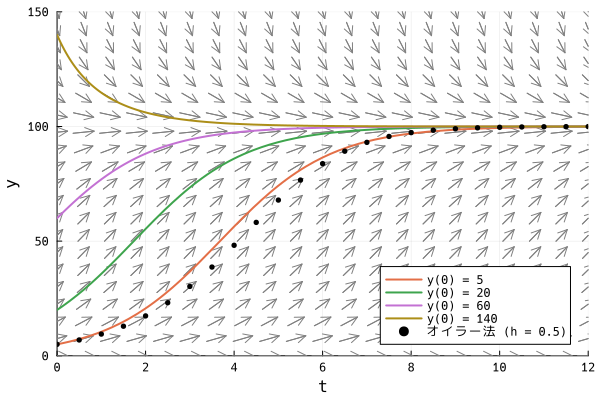

In [24]:
r, K = 0.8, 100.0
slopefield((t, y) -> r * y * (1 - y / K), (0, 12), (0, 150))
for a in (5, 20, 60, 140)
    plot!(t -> L(t, r, K, a), 0, 12; lw=2, label="y(0) = $a")
end

# オイラー法（h = 0.5）と比べる
ts, ys = ode_solve(euler_step, (t, y) -> r * y * (1 - y / K), 0.0, 5.0, 0.5, 24)
scatter!(ts, ys; color=:black, ms=3, label="オイラー法 (h = 0.5)", xlabel="t", legend=:bottomright)

## 8. 2 階の微分方程式：単振動と減衰振動

### 単振動 $y'' = -\omega^2 y$

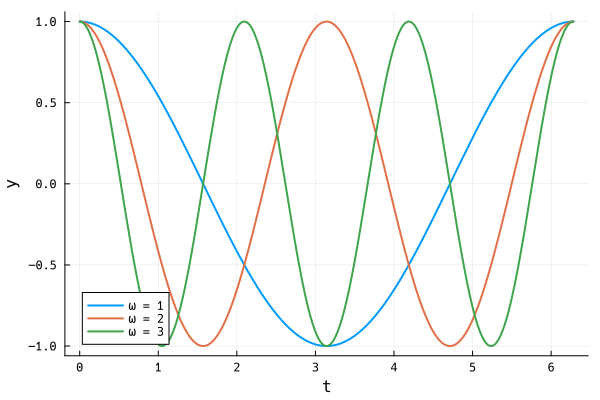

In [25]:
dsolve("y''[t] == -ω^2 y[t]"; x="t")                                       # 一般解
_, osc = dsolve(["y''[t] == -ω^2 y[t]", "y[0] == a", "y'[0] == 0"]; x="t", params=[:ω, :a])

plot(; xlabel="t", ylabel="y")
for ω in (1, 2, 3)
    plot!(t -> osc(t, ω, 1), 0, 2π; lw=2, label="ω = $ω")
end
plot!()

### 減衰振動 $y'' + 2c\,y' + y = 0$

抵抗の強さ $c$ によって，振動しながら減衰（$c < 1$），臨界減衰（$c = 1$），過減衰（$c > 1$）に分かれます。

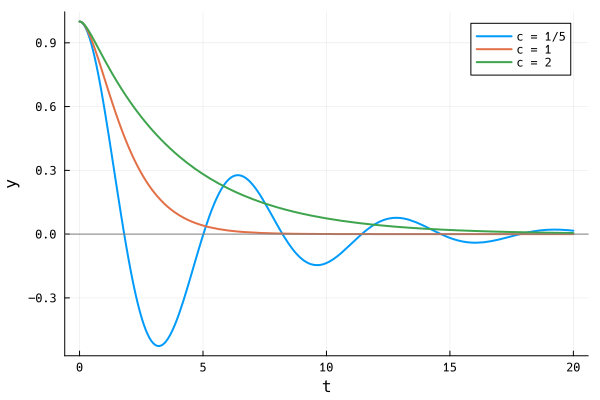

In [26]:
_, d1 = dsolve(["y''[t] + 2 (1/5) y'[t] + y[t] == 0", "y[0] == 1", "y'[0] == 0"]; x="t")
_, d2 = dsolve(["y''[t] + 2 y'[t] + y[t] == 0", "y[0] == 1", "y'[0] == 0"]; x="t")
_, d3 = dsolve(["y''[t] + 4 y'[t] + y[t] == 0", "y[0] == 1", "y'[0] == 0"]; x="t")

plot(d1, 0, 20; lw=2, label="c = 1/5", xlabel="t", ylabel="y")
plot!(d2, 0, 20; lw=2, label="c = 1")
plot!(d3, 0, 20; lw=2, label="c = 2")
hline!([0]; color=:gray, label="")

### 2 階の方程式を数値的に解く

$y'' = -y$ は，$v = y'$ とおくと連立 1 階の方程式 $(y, v)' = (v, -y)$ になります。  
`ode_solve` はベクトルもそのまま扱えます。厳密解は $y = \cos t$，$v = -\sin t$ で，$(y, v)$ は単位円を回ります。

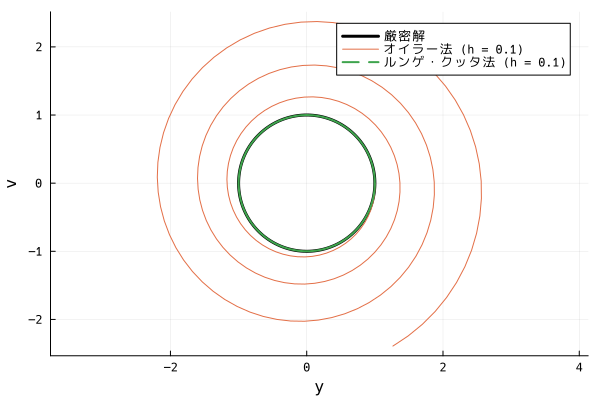

In [27]:
F(t, u) = [u[2], -u[1]]                                  # u = [y, v]
h, n = 0.1, 200

_, ue = ode_solve(euler_step, F, 0.0, [1.0, 0.0], h, n)
_, ur = ode_solve(rk4_step,   F, 0.0, [1.0, 0.0], h, n)

θ = range(0, 2π; length=200)
plot(cos.(θ), -sin.(θ); lw=3, color=:black, label="厳密解", aspect_ratio=1, xlabel="y", ylabel="v")
plot!(first.(ue), last.(ue); label="オイラー法 (h = 0.1)")
plot!(first.(ur), last.(ur); ls=:dash, lw=2, label="ルンゲ・クッタ法 (h = 0.1)")

In [28]:
# t = 20 での y の値：オイラー法は振幅が増えてしまう（エネルギーが保存されない）
first(ue[end]), first(ur[end]), cos(20.0)

(1.2648858131216059, 0.4080966571118259, 0.40808206181339196)

## 9. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **`DSolve` で解けない**：多くの微分方程式は式で解けません。`dsolve` はエラーで知らせるので，`ode_solve` で数値的に解きます。
- **書き方**：未知関数は `y[x]`（角かっこ），導関数は `y'[x]`，等号は `==`。初期条件は `y[0] == 1`，`y'[0] == 0`。
- **Julia の関数の引数の順番**：`(x, パラメータ..., 任意定数...)`。`params=[:k]` を忘れると `UndefVarError: k` になります。
- **文字パラメータで `DomainError`**：$\sqrt{c^2-1}$ のような式に $c<1$ を入れると起こります。8 節の減衰振動のように，数値を入れてから解きます。

┌ Warning: ReplaceAll::reps: 
│                       3                2
│    {DSolve[{y'[x] == x  + Sin[x] + y[x] , y[0] == 0}, y[x], x]}
│      is neither a list of replacement rules nor a valid dispatch table and so
│      cannot be used for replacing.
└ @ MathLink ~/.julia/packages/MathLink/WEvUg/src/eval.jl:16


DSolve では解けませんでした。数値解法を使ってください。


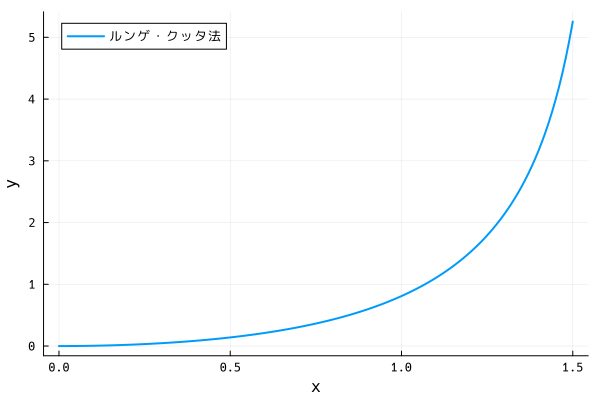

In [29]:
# 式で解けない例：数値解法（RK4）で解く
try
    dsolve(["y'[x] == Sin[x] + y[x]^2 + x^3", "y[0] == 0"])
catch e
    println(e.msg)
end

xs, ys = ode_solve(rk4_step, (x, y) -> sin(x) + y^2 + x^3, 0.0, 0.0, 0.01, 150)
plot(xs, ys; lw=2, label="ルンゲ・クッタ法", xlabel="x", ylabel="y", legend=:topleft)

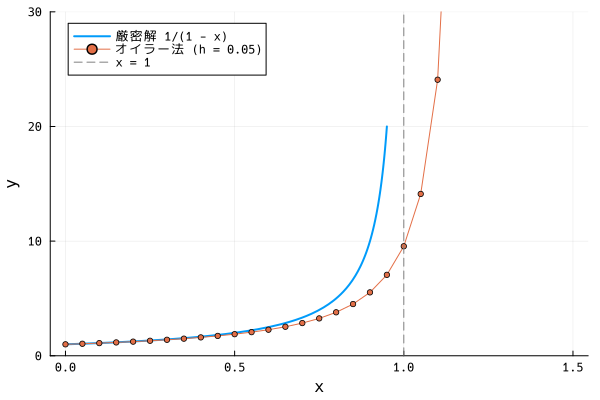

In [30]:
# 解が有限の x で発散する例：y' = y²，y(0) = 1 の解は 1/(1 - x)
_, blow = dsolve(["y'[x] == y[x]^2", "y[0] == 1"])

xs, ys = ode_solve(euler_step, (x, y) -> y^2, 0.0, 1.0, 0.05, 30)        # オイラー法は x = 1 を素通りしてしまう
plot(blow, 0, 0.95; lw=2, label="厳密解 1/(1 - x)", xlabel="x", ylabel="y", ylims=(0, 30))
plot!(xs, ys; marker=:circle, ms=3, label="オイラー法 (h = 0.05)")
vline!([1]; color=:gray, ls=:dash, label="x = 1", legend=:topleft)